# 07 · Python: clase MQTT, hilos, callbacks y ACK

[Índice](00_indice_mqtt.ipynb) · [Anterior](06_python_conversion_y_sintaxis.ipynb) · [Siguiente](09_python_modular.ipynb)

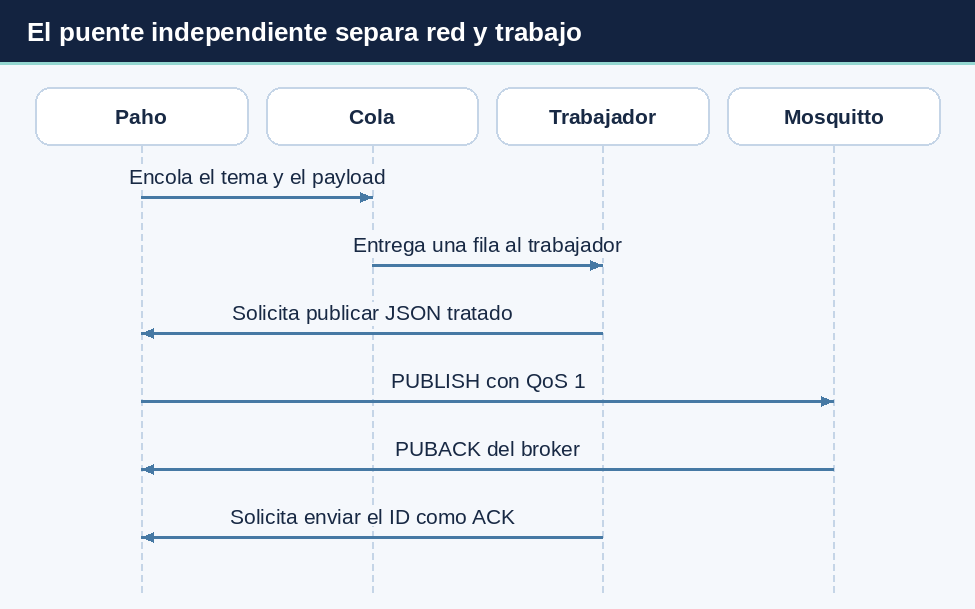

## Dos módulos: transporte y arranque

La clase `CsvMqttBridge` está en `backend/scripts/mqtt_bridge/bridge.py`.
Las funciones `parse_arguments()` y `main()` están en `backend/scripts/mqtt_bridge/cli.py`.
La guarda `if __name__ == "__main__"` está en `backend/scripts/csv_to_json.py`, que llama a main.
No existe una segunda clase de puente en el punto de entrada.

`cli` crea la instancia Paho y se la pasa al constructor de `CsvMqttBridge`.
El puente depende de la conversión, pero el conversor no depende del puente.
En este proyecto «pasar la dependencia» significa simplemente el argumento `client`:
no hay contenedores de inyección ni un framework adicional.

`LOGGER = logging.getLogger(__name__)` se ejecuta en bridge.py. Con la estructura modular,
los mensajes pueden indicar `mqtt_bridge.bridge` o `backend.scripts.mqtt_bridge.bridge`, según la
forma de ejecución. Esa diferencia de nombre no cambia los topics ni el payload.

## Clase `CsvMqttBridge` y sus objetos

La clase agrupa estado y comportamiento de conversión MQTT. `client` es la instancia de Paho que
realiza conexión y transporte. `messages` es una instancia `queue.Queue`, compartida entre el hilo
MQTT y el trabajador. `bridge = CsvMqttBridge(client)` crea el puente y asigna sus callbacks.

`self` es la referencia a la instancia en cada método. Al escribir `client.on_message = self.on_message`
se asigna un método ligado a esa instancia: Paho pasa los argumentos del callback; Python ya conoce
qué `self` usar. No hay que llamar `self.on_message()` al registrarlo.

El hilo de `loop_forever()` debe poder seguir atendiendo paquetes, incluido PUBACK. Por eso esperar
`wait_for_publish()` en el callback de recepción bloquearía el trabajo que debe recibir esa confirmación.
El callback encola y sale; el trabajador convierte y espera fuera del hilo MQTT.

## `CsvMqttBridge.__init__`


**Parámetros:** `self` y `client: mqtt.Client`. **Retorno:** None.
Conserva el cliente en `self.client`, crea una cola de capacidad 100 y registra los callbacks.
La anotación `queue.Queue[tuple[str, bytes]]` describe elementos de dos partes: topic y cuerpo.
No inicia el hilo ni conecta al broker; esas acciones ocurren después.

```python
def __init__(self, client: mqtt.Client) -> None:
    self.client = client
    self.messages: queue.Queue[tuple[str, bytes]] = queue.Queue(
        maxsize=MESSAGE_QUEUE_SIZE
    )
    self.client.on_connect = self.on_connect
    self.client.on_message = self.on_message
```

## `CsvMqttBridge.on_connect`


**Parámetros:** `self`; `client`, cliente que invoca; `userdata`, datos opcionales del usuario;
`flags`, información de sesión; `reason_code`, resultado de conexión; `properties`, propiedades MQTT
según protocolo/API. **Retorno:** None. Los parámetros no usados se mantienen porque pertenecen a la
firma de callback de Paho VERSION2.

Si reason_code no es 0 registra error y retorna. Si fue exitoso, llama
`client.subscribe(RAW_TOPIC_FILTER,qos=1)` y registra conexión. Se repite al reconectar para restablecer
la suscripción. Este mensaje de log no verifica por separado la respuesta SUBACK del broker.

```python
def on_connect(self, client, userdata, flags, reason_code, properties) -> None:
    """Restablece la suscripcion al conectar o reconectar al broker."""
    if reason_code != 0:
        LOGGER.error("Conexion rechazada: %s", reason_code)
        return

    client.subscribe(RAW_TOPIC_FILTER, qos=1)
    LOGGER.info("Conectado; escuchando %s", RAW_TOPIC_FILTER)
```

## `CsvMqttBridge.on_message`


**Parámetros:** `self`, `client`, `userdata` y `message` (objeto recibido de Paho).
**Retorno:** None. Usa `message.topic` como str y `message.payload` como bytes.
`put_nowait((topic,payload))` agrega la tupla sin esperar espacio. Si la cola está llena levanta
`queue.Full`; se registra advertencia y no hay ACK de aplicación. El ESP32 conserva la fila y reintenta.
La cola de Python es RAM: no sustituye la persistencia del ESP32.

```python
def on_message(self, client, userdata, message) -> None:
    """Encola el CSV sin bloquear el procesamiento de paquetes MQTT."""
    try:
        self.messages.put_nowait((message.topic, message.payload))
    except queue.Full:
        LOGGER.warning("Cola llena; el ESP32 reintentara sin recibir ACK")
```

## `CsvMqttBridge.publish_reading`


**Parámetros:** `self` y `reading: ConvertedReading`. **Retorno:** None.
Forma el prefijo a partir del ID validado. `publish(topic,json_payload,qos=1)` devuelve un objeto
MQTTMessageInfo, aquí llamado `publication`. `wait_for_publish(timeout=10)` espera hasta el PUBACK
o el límite configurado; no debe interpretarse su retorno como éxito. Se comprueba `is_published()`.

Si no está confirmado, registra advertencia y retorna sin ACK. Si lo está, publica `reading.record_id`
en `/ack`, también QoS 1. Ese segundo envío no se espera aquí; si falla o se pierde, el ESP32 volverá
a enviar la fila. Que el ACK se publique no implica que ya se haya guardado el cursor en la placa.
No implementa caché de IDs: reintentos pueden generar JSON duplicados.

```python
def publish_reading(self, reading: ConvertedReading) -> None:
    """Confirma al ESP32 solo despues del PUBACK del JSON tratado."""
    topic_prefix = f"dispositivo/{reading.device_id}"
    publication = self.client.publish(
        f"{topic_prefix}/tratado", reading.json_payload, qos=1
    )
    publication.wait_for_publish(timeout=PUBLISH_TIMEOUT_SECONDS)

    if not publication.is_published():
        LOGGER.warning("Sin confirmacion del broker; CSV pendiente")
        return

    self.client.publish(f"{topic_prefix}/ack", reading.record_id, qos=1)
```

## `CsvMqttBridge.process_messages`


**Parámetros:** solo `self`. **Retorno anotado:** None; normalmente permanece dentro de `while True`.
`self.messages.get()` bloquea al trabajador hasta tener una tupla; no bloquea el hilo de red.
Desempaqueta topic/payload, convierte y publica. Captura ValueError, KeyError, UnicodeError,
RuntimeError y csv.Error, registra el fallo y continúa con el siguiente elemento.

El bloque `finally` llama siempre a `task_done()` para equilibrar el get de la cola; eso significa
que terminó el trabajo de ese elemento, no que el ESP32 recibió un ACK. El archivo original sigue
en la placa si el procesamiento falla. Excepciones ajenas a la lista no se capturan aquí y podrían
terminar el trabajador: no hay un supervisor que lo reinicie.

```python
def process_messages(self) -> None:
    """Mantiene pendientes en el ESP32 las lecturas que no se procesen."""
    while True:
        topic, payload = self.messages.get()
        try:
            reading = convert_csv_message(topic, payload)
            self.publish_reading(reading)
        except (ValueError, KeyError, UnicodeError, RuntimeError, csv.Error) as error:
            LOGGER.error("CSV no procesado: %s", error)
        finally:
            self.messages.task_done()
```

## `CsvMqttBridge.start`


**Parámetros:** solo `self`. **Retorno:** None.
Construye `threading.Thread(target=self.process_messages,name="csv-message-worker",daemon=True)`.
`target` recibe la función sin paréntesis. El nombre facilita diagnosticar el hilo. `daemon=True`
permite que no mantenga vivo el proceso cuando termina el hilo principal; un trabajo en curso puede
interrumpirse al salir. `worker.start()` inicia la ejecución concurrente.
No se debe llamar repetidamente para crear múltiples consumidores sin revisar sus efectos.

```python
def start(self) -> None:
    worker = threading.Thread(
        target=self.process_messages,
        name="csv-message-worker",
        daemon=True,
    )
    worker.start()
```

## `cli.parse_arguments()`

**Parámetros explícitos:** ninguno. **Retorno:** `argparse.Namespace`.
`ArgumentParser(description=__doc__)` toma el docstring de cli.py para la ayuda.
`--host` es texto y usa `localhost` si se omite. `--port` convierte con `type=int` y
usa 1883 por defecto. `parse_args()` lee `sys.argv`; los argumentos reales pueden ser
`--host 127.0.0.1 --port 1883`. Un texto que no sea entero se rechaza mediante argparse;
no se valida aquí el rango del puerto ni que el servidor esté disponible.

El `Namespace` conserva `arguments.host` y `arguments.port`, que main pasa como argumentos
a `client.connect`. El keepalive se obtiene separadamente de settings.py. Estos tres datos
no se cargan del config.json del ESP32. No se usan usuario ni contraseña MQTT.

```python
def parse_arguments() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--host", default="localhost")
    parser.add_argument("--port", type=int, default=1883)
    return parser.parse_args()
```

## `cli.main()` y punto de entrada

**Parámetros:** ninguno explícito. **Retorno:** None.
Importa Paho en ejecución, procesa argumentos y activa logging INFO. Construye
`mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)`: VERSION2 selecciona la firma de callbacks, no
significa MQTT versión 2 ni activa MQTT 5. La llamada usa el protocolo predeterminado de Paho.

El cliente Python se conecta sin usuario ni contraseña MQTT. La clave PASS de config.json corresponde al WiFi del ESP32, no al broker.
Crea el puente, arranca trabajador, conecta con host/puerto/keepalive=60 y ejecuta loop_forever.
Ese bucle atiende MQTT y las reconexiones ordinarias después de conectar; un fallo de `connect`
inicial sucede antes del try y no se maneja con un reintento propio del script.
Ctrl+C levanta KeyboardInterrupt; el except desconecta limpiamente el cliente.

`if __name__ == "__main__": main()` ejecuta el programa cuando se lanza el archivo; al importarlo
para usar convert_csv_message no abre una conexión MQTT.

```python
def main() -> None:
    import paho.mqtt.client as mqtt

    arguments = parse_arguments()
    logging.basicConfig(level=logging.INFO)
    client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)

    bridge = CsvMqttBridge(client)
    bridge.start()
    client.connect(arguments.host, arguments.port, MQTT_KEEPALIVE_SECONDS)

    try:
        client.loop_forever()
    except KeyboardInterrupt:
        client.disconnect()
```

```python
"""Punto de entrada del conversor CSV a JSON por MQTT."""

if __package__:
    from .mqtt_bridge.cli import main
else:
    from mqtt_bridge.cli import main


if __name__ == "__main__":
    main()

```

### Métodos de bibliotecas que usa el puente

| Método | Argumentos usados | Para qué sirve |
|---|---|---|
| `mqtt.Client` | CallbackAPIVersion.VERSION2 | Construir cliente con callbacks VERSION2. |
| `connect` | Host, puerto, keepalive | Iniciar conexión TCP/MQTT. |
| `subscribe` | Filtro, qos=1 | Pedir mensajes crudos de todos los IDs. |
| `publish` | Topic, payload, qos=1 | Encolar/enviar mensaje y obtener su estado de publicación. |
| `wait_for_publish` | timeout=10 | Esperar confirmación fuera del hilo MQTT. |
| `is_published` | Sin argumentos | Consultar si se confirmó ese envío. |
| `loop_forever` | Sin argumentos | Atender red en el hilo llamador. |
| `disconnect` | Sin argumentos | Solicitar desconexión limpia. |
| `queue.Queue` | maxsize=100 | Crear cola limitada entre hilos. |
| `put_nowait` / `get` / `task_done` | Tupla / ninguno / ninguno | Producir, consumir y marcar finalización local. |
| `LOGGER.info/warning/error` | Mensaje y valores `%s` | Registrar sin construir manualmente todos los textos. |

En `LOGGER.error("CSV no procesado: %s", error)` el logger aplica el formato; no es una llamada
a printf ni a una f-string. El uso de try/except/finally evita perder el balance de la cola ante
un CSV inválido. No hace que las escrituras de ESP32 y broker sean una sola transacción.

[Índice](00_indice_mqtt.ipynb) · [Anterior](06_python_conversion_y_sintaxis.ipynb) · [Siguiente](09_python_modular.ipynb)